# 18 — Families of real glitches: unsupervised clustering and which ones fool each detector

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extension 24, Gravity-Spy style but unsupervised and without labels. Takes the validation and test noise windows, keeps the 4 % with the largest bank statistic (the windows that can raise a false alarm), describes each by its log-spectrogram, reduces with PCA, clusters with k-means (k chosen by silhouette) and characterises every cluster (peak frequency, duration, amplitude, epoch). Then it measures, per cluster, the fraction of windows that exceed the threshold of FAP 10⁻² (validation noise) for the sine-Gaussian bank, the bank with χ² veto (notebook 16 convention) and the fresh CNN of notebook 07.

**What it does not do.** There are no human labels, so the clusters are *morphological families*, not named glitch classes (blip, whistle, scattered light); the selection is by the bank statistic, so glitches that the bank ignores are not represented; the thresholds are set on the same validation windows that contribute to the candidates (by construction ≈ 1 % of validation windows exceed them).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import spectrogram
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import seq_models as sm
import gwosc_tools as g
g.style()
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
V, ID = {}, {}
for sp in ("val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
def cscan(n): d = np.load(os.path.join(g.CACHE, f"scan03_{n}.npz")); return {k: d[k] for k in d.files}
SC = {sp: cscan(sp) for sp in V}
v = np.concatenate([V["val"], V["test"]]); cid = np.concatenate([ID["val"], ID["test"]]); rho2 = np.concatenate([SC["val"]["rho2"], SC["test"]["rho2"]])
isval = np.r_[np.ones(len(V["val"]), bool), np.zeros(len(V["test"]), bool)]
sel = np.where(rho2 >= np.quantile(rho2, 0.96))[0]; print(len(sel), "candidate glitch windows of", len(v))

649 candidate glitch windows of 16224


In [2]:
def spec(w):
    f, t, Sx = spectrogram(w, fs=g.FS, nperseg=64, noverlap=48, window="hann"); return f, t, np.log10(Sx + 1e-3)
f, t, _ = spec(v[0]); SP = np.stack([spec(v[i])[2] for i in sel]); SP = np.clip(SP - np.median(SP, axis=(1, 2), keepdims=True), -1, 3); print(SP.shape)   # shape of the time-frequency excess, not the overall level; clipped so that 2-3 enormous glitches do not make a cluster of their own
Z = StandardScaler().fit_transform(SP.reshape(len(sel), -1)); Zp = PCA(n_components=12, random_state=0).fit_transform(Z)
far = np.linalg.norm(Zp, axis=1) > np.quantile(np.linalg.norm(Zp, axis=1), 0.97)      # the most atypical 3 %: an "extreme" family of its own (a few enormous glitches would otherwise make singleton clusters)
sil = {k: silhouette_score(Zp[~far], KMeans(k, n_init=10, random_state=0).fit_predict(Zp[~far])) for k in range(3, 9)}
K0 = max(sil, key=sil.get); lab = np.full(len(sel), K0); lab[~far] = KMeans(K0, n_init=20, random_state=0).fit_predict(Zp[~far]); K = K0 + 1
print("silhouette (typical windows):", {k: round(s, 3) for k, s in sil.items()}, "-> %d families + 1 extreme family (%d windows)" % (K0, far.sum()))


(649, 33, 61)


silhouette (typical windows): {3: 0.084, 4: 0.081, 5: 0.075, 6: 0.077, 7: 0.073, 8: 0.073} -> 3 families + 1 extreme family (20 windows)


In [3]:
def desc(i):
    w = v[i]; env = np.abs(w) ** 2; c = np.cumsum(env) / env.sum(); dur = (np.searchsorted(c, .95) - np.searchsorted(c, .05)) / g.FS
    P = np.abs(np.fft.rfft(w)) ** 2; fp = g.FREQ[(g.FREQ >= 30) & (g.FREQ <= 500)][np.argmax(P[(g.FREQ >= 30) & (g.FREQ <= 500)])]
    return dict(vmax=np.abs(w).max(), dur90=dur, fpeak=fp)
D = pd.DataFrame([desc(i) for i in sel]); D["cluster"] = lab; D["chunk"] = cid[sel]; D["rho2"] = rho2[sel]
# detectors
nets = [sm.train_variant("cnn_fresh", None, None, seed=s, verbose=False)[0] for s in (0, 1)]
cnn = np.mean([m.predict(sm.clip(v)[..., None], verbose=0, batch_size=1024)[:, 0] for m in nets], 0)
B160 = {i: g.SGBank(CH[i]["S1"]) for i in CH}
chi = np.zeros(len(sel)); scs = {}
for c in np.unique(cid[sel]):
    m = cid[sel] == c; o = B160[c].scan(g.to_bins(v[sel][m])); idx = g.template_index(B160[c], o["f0"], o["Q"])
    chi[m] = g.allen_chi2(B160[c], g.to_bins(v[sel][m]), o["tau"], idx)
thr_b = g.threshold_at_far(rho2[isval], 1e-2); thr_c = g.threshold_at_far(cnn[isval], 1e-2)
D["bank"] = rho2[sel] > thr_b; D["bank+chi2<3"] = (rho2[sel] > thr_b) & (chi < 3); D["CNN"] = cnn[sel] > thr_c
Tab = D.groupby("cluster").agg(n=("rho2", "size"), vmax=("vmax", "median"), dur90_ms=("dur90", lambda x: 1e3 * np.median(x)), fpeak=("fpeak", "median"),
                               frac_chunk_main=("chunk", lambda x: x.value_counts(normalize=True).iloc[0]), bank=("bank", "mean"), bank_chi2=("bank+chi2<3", "mean"), CNN=("CNN", "mean"))
Tab.round(2)

,n,vmax,dur90_ms,fpeak,frac_chunk_main,bank,bank_chi2,CNN
cluster,,,,,,,,
0,168,3.46,895.02,113.0,0.38,0.30,0.28,0.07
1,218,3.33,899.41,218.0,0.29,0.19,0.19,0.05
2,243,3.43,894.53,280.0,0.27,0.16,0.16,0.05
3,20,4.67,875.49,104.0,0.50,0.95,0.05,0.05


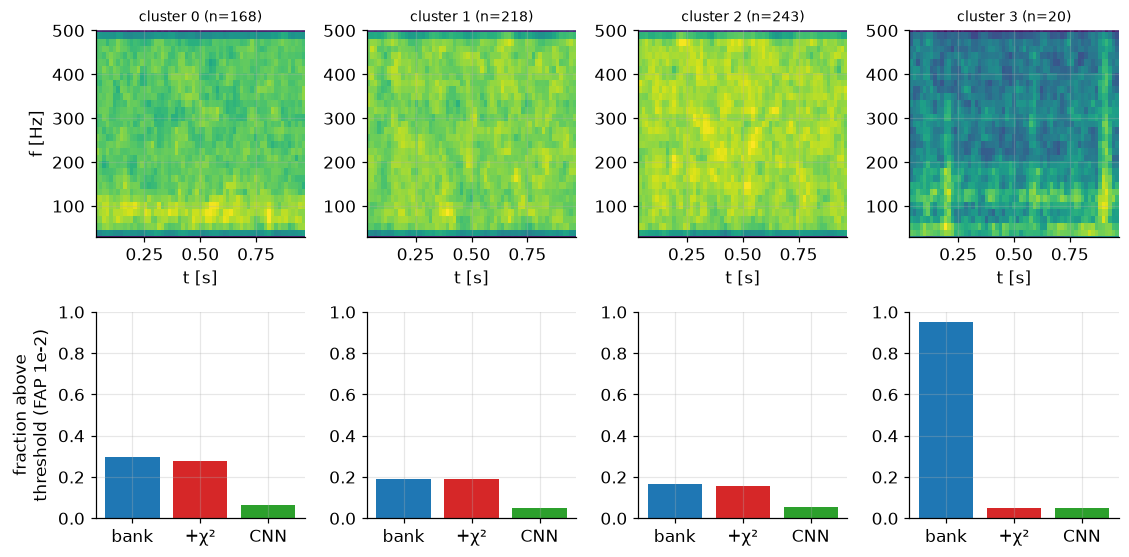

In [4]:
fig, ax = plt.subplots(2, K, figsize=(2.6 * K, 5.2), squeeze=False)
for c in range(K):
    ax[0, c].imshow(SP[lab == c].mean(0), origin="lower", aspect="auto", extent=[t[0], t[-1], f[0], f[-1]], cmap="viridis"); ax[0, c].set_title(f"cluster {c} (n={int((lab == c).sum())})", fontsize=9)
    ax[0, c].set_xlabel("t [s]"); ax[0, c].set_ylim(30, 500)
    r = Tab.loc[c]; ax[1, c].bar(["bank", "+χ²", "CNN"], [r.bank, r.bank_chi2, r.CNN], color=[g.COLORS["freq"], g.COLORS["bayes"], "C2"]); ax[1, c].set_ylim(0, 1)
ax[0, 0].set_ylabel("f [Hz]"); ax[1, 0].set_ylabel("fraction above\nthreshold (FAP 1e-2)")
fig.tight_layout(); g.savefig(fig, "fig18_glitch_families"); plt.show()
g.save_json(dict(K=K, silhouette={str(k): float(s) for k, s in sil.items()}, clusters=Tab.reset_index().to_dict("records"), n_candidates=int(len(sel))), "18_summary.json")

## Output and next step

`results/18_summary.json`, `figures/fig18_glitch_families`. The table shows which morphological families of real glitches are alarms for the bank, for the bank with the χ² test and for the network. Next: unfolding of the total-mass distribution (extension 49).